# Window-state rollout probe

This evaluates the learned window-state transition model on held-out trajectories. The saved transition chunks are intentionally flat pairs, so ordered states are reconstructed from the same held-out raw trajectories: $S_t = E(f_{2t:2t+8})$.

In [1]:
# import math
# import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

# parent_dir = str(Path('../..').resolve())
# if parent_dir not in sys.path:
#     sys.path.append(parent_dir)
# from dmc_dataset.dataset import get_dataset


from rvsablation.ae import FSQ_VideoVAE
from rvsablation.core import _TransformerStack
from rvsablation.jepa import FSQ_V_JEPA
from rvsablation.utils import get_3d_sincos_pos_embed, read_config, seed_everything, get_dataset

DATA = "walker" # why it works so well with cheetah lmao persistence maybe shows cheetah doesnt change between scenes that much
MODEL_RUNS = {
    'ae': 'fsq_videovae_run_1', 
    'jepa': 'fsq_v_jepa_run_1', 
    'no-op ae': 'fsq_videovae_run_1', 
    'no-op jepa': 'fsq_v_jepa_run_1',
}
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_TRAJECTORIES = 250
rng = seed_everything(978)

🌱 Global seed set to 978


In [2]:
class WindowTransitionProbe(nn.Module):
    def __init__(self, spatial_grid_size, temporal_grid_size, latent_dim, action_dim, hidden_dim, depth, attention_dim, attention_num_heads):
        super().__init__()
        self.latent_proj = nn.Linear(latent_dim, hidden_dim, bias=False)
        self.action_proj = nn.Linear(action_dim, hidden_dim, bias=False)
        self.out_proj = nn.Linear(hidden_dim, latent_dim, bias=False)
        self.stack = _TransformerStack(hidden_dim, depth, attention_dim, attention_num_heads)
        pos = get_3d_sincos_pos_embed(hidden_dim, temporal_grid_size, spatial_grid_size)
        self.register_buffer('pos', pos.unsqueeze(0), persistent=False)

    def forward(self, x, action):
        x = self.latent_proj(x)
        action = self.action_proj(action).unsqueeze(1)
        return self.out_proj(self.stack(x + action + self.pos, attn_mask=None))

In [3]:
class Dummy(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def forward(self, x, a):
        return x

In [4]:
_, testset, _, _ = get_dataset(
    rng=rng,
    root=f'../data/{DATA}_trajs_h5/data.h5',
    sample_num_frames=100,
    sample_num_clips=1,
    data_num_traj=25000,
    data_num_frames=100,
    dataset=DATA
)

sample_frames, sample_actions, *_ = testset[0]

def load_model_pair(model_type: str, run_name):
    mt = model_type.split(' ')[-1]
    run_dir = Path('..') / f'{mt}_runs' / run_name
    model_config = read_config(run_dir / 'confs' / 'model_config.json')
    run_config = read_config(run_dir / 'confs' / 'run_config.json')
    encoder_class = FSQ_VideoVAE if model_type in ['ae', 'no-op ae'] else FSQ_V_JEPA
    encoder = encoder_class(**model_config)
    encoder.load_state_dict(torch.load(run_dir / 'weights' / 'model_4.9m.pt', map_location=DEVICE))
    encoder = encoder.to(DEVICE).eval()

    num_frames_clip = run_config['sample_num_frames']
    tubelet_size = model_config['tubelet_size']
    num_tubelets = num_frames_clip // tubelet_size
    if model_type in ['no-op ae', 'no-op jepa']:
        transition_model = Dummy().to(DEVICE)
    else: 
        transition_model = WindowTransitionProbe(
            spatial_grid_size=encoder.encoder.spatial_grid_size,
            temporal_grid_size=num_tubelets,
            latent_dim=model_config['fsq_dim'],
            action_dim=sample_actions.shape[-1],
            hidden_dim=384, depth=6, attention_dim=384, attention_num_heads=6,
        ).to(DEVICE)
        transition_model.load_state_dict(
            torch.load(run_dir / 'transition_window' / 'transition_window_best.pt', map_location=DEVICE)
        )
    return encoder, transition_model.eval(), num_frames_clip, tubelet_size

model_pairs = {
    model_type: load_model_pair(model_type, run_name)
    for model_type, run_name in MODEL_RUNS.items()
}

<>:55: SyntaxWarning: invalid escape sequence '\p'
<>:55: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_31351/3865798766.py:55: SyntaxWarning: invalid escape sequence '\p'
  ax.text(0.05, 0.02, f'Mean $\pm$ SEM over {num_trajectories} trajectories', transform=ax.transAxes, fontsize=9, color='#555555')


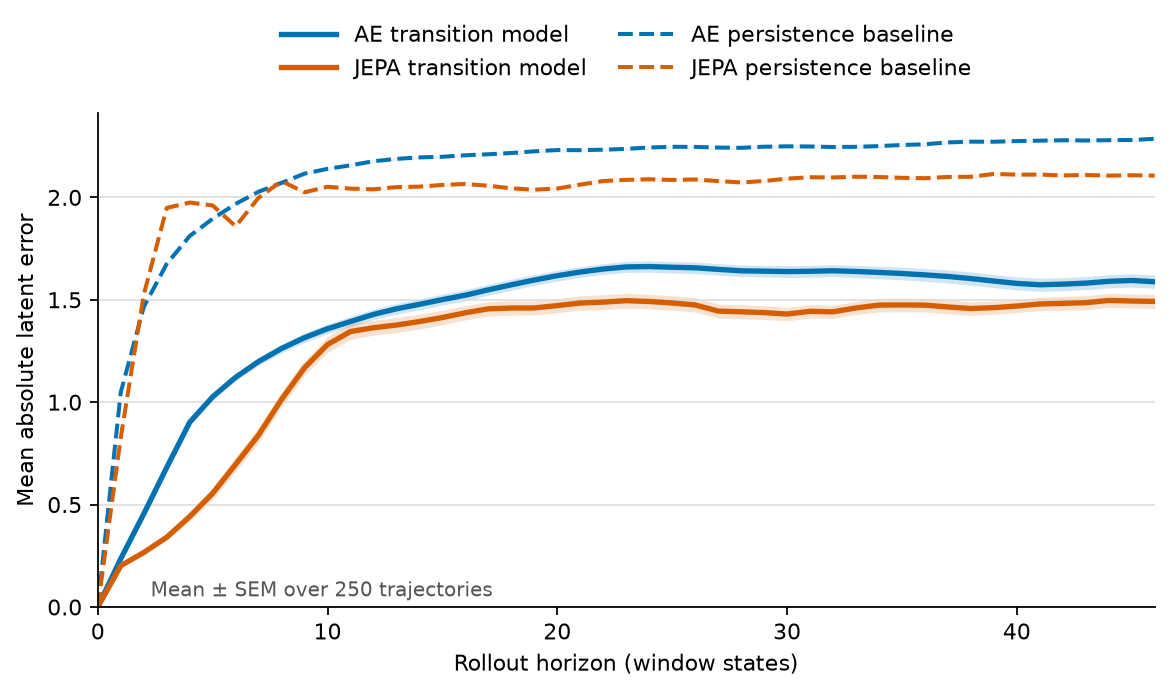

ae         mean error over nonzero horizons: 1.4534
jepa       mean error over nonzero horizons: 1.2871
no-op ae   mean error over nonzero horizons: 2.1503
no-op jepa mean error over nonzero horizons: 2.0264


In [5]:
@torch.no_grad()
def rollout_error_for_trajectory(sample, encoder, transition_model, num_frames_clip, tubelet_size):
    frames, actions, *_ = sample
    window_index = torch.arange(frames.size(0)).unfold(0, num_frames_clip, tubelet_size)

    # Ground-truth states are independently encoded sliding windows.
    states = encoder(frames[window_index].to(DEVICE)).float()
    departing_actions = actions[window_index][:-1, -1].to(DEVICE, dtype=torch.float32)

    rollout = [states[0]]
    state = states[0]
    for action in departing_actions:
        state = transition_model(state.unsqueeze(0), action.unsqueeze(0)).squeeze(0)
        rollout.append(state)

    rollout = torch.stack(rollout)
    assert rollout.shape == states.shape
    return F.l1_loss(rollout, states, reduction='none').mean(dim=(1, 2)).cpu()


num_trajectories = min(NUM_TRAJECTORIES, len(testset))
rollout_errors = {}
for model_type, (encoder, transition_model, num_frames_clip, tubelet_size) in model_pairs.items():
    rollout_errors[model_type] = torch.stack([
        rollout_error_for_trajectory(testset[index], encoder, transition_model, num_frames_clip, tubelet_size)
        for index in range(num_trajectories)
    ])

horizon = torch.arange(next(iter(rollout_errors.values())).size(1))
summary = {
    name: (errors.mean(dim=0), errors.std(dim=0, unbiased=True) / num_trajectories ** 0.5)
    for name, errors in rollout_errors.items()
}

# Same colour denotes the representation; line style denotes the transition rule.
style = {
    'ae': {'color': '#0072B2', 'label': 'AE transition model', 'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.18},
    'no-op ae': {'color': '#0072B2', 'label': 'AE persistence baseline', 'linestyle': '--', 'linewidth': 1.8, 'alpha': 0.08},
    'jepa': {'color': '#D55E00', 'label': 'JEPA transition model', 'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.18},
    'no-op jepa': {'color': '#D55E00', 'label': 'JEPA persistence baseline', 'linestyle': '--', 'linewidth': 1.8, 'alpha': 0.08},
}

fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=160, layout='constrained')
for name in ('ae', 'jepa', 'no-op ae', 'no-op jepa'):
    mean_error, sem_error = summary[name]
    kwargs = style[name]
    ax.plot(horizon, mean_error, **{key: kwargs[key] for key in ('color', 'label', 'linestyle', 'linewidth')})
    ax.fill_between(horizon, mean_error - sem_error, mean_error + sem_error, color=kwargs['color'], alpha=kwargs['alpha'], linewidth=0)

ax.set(xlabel='Rollout horizon (window states)', ylabel='Mean absolute latent error', xlim=(0, horizon[-1].item()), ylim=(0, None))
ax.set_xticks(torch.arange(0, horizon[-1].item() + 1, 10))
ax.grid(axis='y', color='#D9D9D9', linewidth=0.8, alpha=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.22), columnspacing=1.4, handlelength=2.5)
ax.text(0.05, 0.02, f'Mean $\pm$ SEM over {num_trajectories} trajectories', transform=ax.transAxes, fontsize=9, color='#555555')
plt.show()

for model_type in ('ae', 'jepa', 'no-op ae', 'no-op jepa'):
    print(f'{model_type:10s} mean error over nonzero horizons: {summary[model_type][0][1:].mean():.4f}')

<>:63: SyntaxWarning: invalid escape sequence '\p'
<>:63: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_31351/26417894.py:63: SyntaxWarning: invalid escape sequence '\p'
  ax.text(0.05, 0.02, f'Mean $\pm$ SEM over {num_trajectories} trajectories', transform=ax.transAxes, fontsize=9, color='#555555')


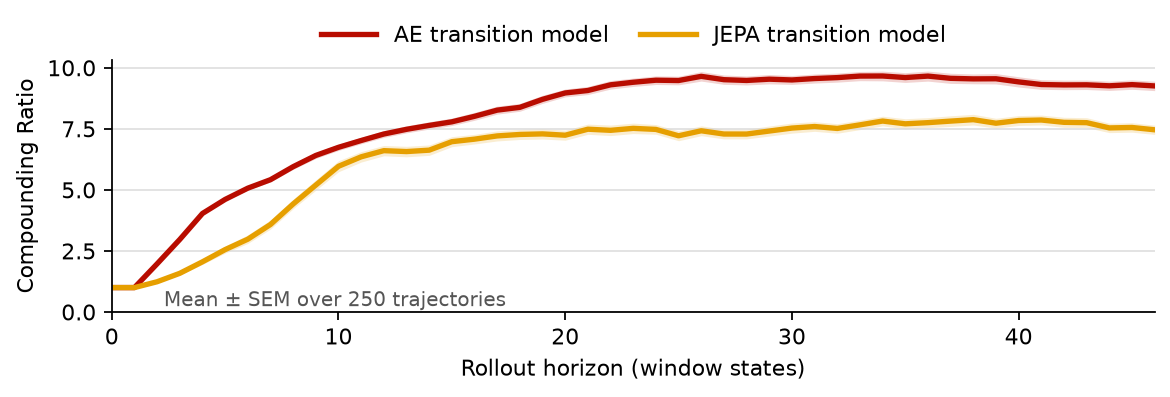

ae         mean CR over nonzero horizons: 8.0381
jepa       mean CR over nonzero horizons: 6.4596


In [11]:
@torch.no_grad()
def compounding_ratio_for_trajectory(sample, encoder, transition_model, num_frames_clip, tubelet_size):
    frames, actions, *_ = sample
    window_index = torch.arange(frames.size(0)).unfold(0, num_frames_clip, tubelet_size)

    # Ground-truth states are independently encoded sliding windows.
    states = encoder(frames[window_index].to(DEVICE)).float()
    departing_actions = actions[window_index][:-1, -1].to(DEVICE, dtype=torch.float32)

    rollout = [states[0]]
    teacher_forced = [states[0]]
    state = states[0]
    for i, action in enumerate(departing_actions):
        state = transition_model(state.unsqueeze(0), action.unsqueeze(0)).squeeze(0)
        tf_state = transition_model(states[i].unsqueeze(0), action.unsqueeze(0)).squeeze(0)
        rollout.append(state)
        teacher_forced.append(tf_state)

    rollout = torch.stack(rollout)
    tf_rollout = torch.stack(teacher_forced)
    assert rollout.shape == states.shape == tf_rollout.shape
    open_loop_error = F.l1_loss(rollout, states, reduction='none').mean(dim=(1, 2)).cpu()
    teacher_forced_error = F.l1_loss(tf_rollout, states, reduction='none').mean(dim=(1, 2)).cpu()
    compounding_ratio = torch.ones_like(open_loop_error) # Initialize with 1.0 (handles step 0 automatically)
    compounding_ratio[1:] = open_loop_error[1:] / (teacher_forced_error[1:] + 1e-8)
    return compounding_ratio


num_trajectories = min(NUM_TRAJECTORIES, len(testset))
compounding_ratios = {}
for model_type, (encoder, transition_model, num_frames_clip, tubelet_size) in model_pairs.items():
    if model_type.startswith("no-op"):
        continue
    compounding_ratios[model_type] = torch.stack([
        compounding_ratio_for_trajectory(testset[index], encoder, transition_model, num_frames_clip, tubelet_size)
        for index in range(num_trajectories)
    ])

horizon = torch.arange(next(iter(compounding_ratios.values())).size(1))

summary = {
    name: (crs.mean(dim=0), crs.std(dim=0, unbiased=True) / num_trajectories ** 0.5)
    for name, crs in compounding_ratios.items()
}

style = {
    'ae': {'color': "#B80C00", 'label': 'AE transition model', 'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.18},
    'jepa': {'color': '#E69F00', 'label': 'JEPA transition model', 'linestyle': '-', 'linewidth': 2.4, 'alpha': 0.18},
}

fig, ax = plt.subplots(figsize=(7.2, 2.35), dpi=160, layout='constrained')
for name in ('ae', 'jepa'):
    mean_error, sem_error = summary[name]
    kwargs = style[name]
    ax.plot(horizon, mean_error, **{key: kwargs[key] for key in ('color', 'label', 'linestyle', 'linewidth')})
    ax.fill_between(horizon, mean_error - sem_error, mean_error + sem_error, color=kwargs['color'], alpha=kwargs['alpha'], linewidth=0)

ax.set(xlabel='Rollout horizon (window states)', ylabel='Compounding Ratio', xlim=(0, horizon[-1].item()), ylim=(0, None))
ax.set_xticks(torch.arange(0, horizon[-1].item() + 1, 10))
ax.grid(axis='y', color='#D9D9D9', linewidth=0.8, alpha=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.22), columnspacing=1.4, handlelength=2.5)
ax.text(0.05, 0.02, f'Mean $\pm$ SEM over {num_trajectories} trajectories', transform=ax.transAxes, fontsize=9, color='#555555')
plt.show()

for model_type in ('ae', 'jepa'):
    print(f'{model_type:10s} mean CR over nonzero horizons: {summary[model_type][0][1:].mean():.4f}')

In [12]:
fig.savefig("../pics/transition_compounding_ratio_walker_r1.pdf", format="pdf", bbox_inches="tight")